In [1]:
file = '/media/smartrue/HHD1/George/models/PPC/PPC_sat_ver0/pv/Ptolemaida/multi-output/model_ver0/DATA/predictions_regressors_eval.pickle'


In [31]:
import joblib

predictions_all = joblib.load(file)

In [3]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

In [32]:
predictions_all['clusters']['RBF']['averages'].keys()

dict_keys(['CNN_average', 'TIMM_average', 'MLP_average', 'CatBoost_average', 'bcp_average', 'kmeans_average'])

In [39]:
predictions = predictions_all['clusters']['RBF']['averages']['kmeans_average']

In [9]:
from case_study.short_term_image.configuration.config import config
from eforecast.init.initialize import initializer
static_data = initializer(config())

Areas created successfully
Static data of all projects created


In [10]:
from eforecast.datasets.data_feeder import DataFeeder
data_feeder = DataFeeder(static_data, train=False)
y = data_feeder.feed_target(inverse=False)

In [40]:
predictions.columns = y.columns

In [41]:
dates = y.index.intersection(predictions.index)

<Axes: >

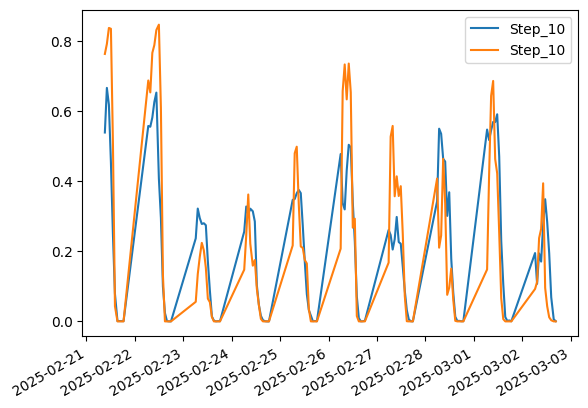

In [44]:
pd.concat([predictions.loc[dates[1000:1500:4], y.columns[10]], y.loc[dates[1000:1500:4], y.columns[10]]], axis=1).plot()

In [26]:
dates

DatetimeIndex(['2025-02-01 06:15:00', '2025-02-01 06:30:00',
               '2025-02-01 06:45:00', '2025-02-01 07:00:00',
               '2025-02-01 07:15:00', '2025-02-01 07:30:00',
               '2025-02-01 07:45:00', '2025-02-01 08:00:00',
               '2025-02-01 08:15:00', '2025-02-01 08:30:00',
               ...
               '2025-03-19 18:30:00', '2025-03-19 18:45:00',
               '2025-03-19 19:00:00', '2025-03-20 05:15:00',
               '2025-03-20 05:30:00', '2025-03-20 05:45:00',
               '2025-03-20 06:00:00', '2025-03-20 06:15:00',
               '2025-03-20 06:30:00', '2025-03-20 06:45:00'],
              dtype='datetime64[ns]', length=1940, freq=None)

In [78]:
pv_ts = pd.read_csv('/home/smartrue/Dropbox/current_codes/PycharmProjects/case_study/data/pv_original.csv', index_col=0, parse_dates=True)
pv_ts.index = pd.to_datetime(pv_ts.index, utc=True).tz_convert('CET').tz_localize(None)
pv_ts = pv_ts.sum(axis=1).to_frame('original')


In [71]:
pv_ts = pv_ts.shift(-10).loc[dates]

<Axes: >

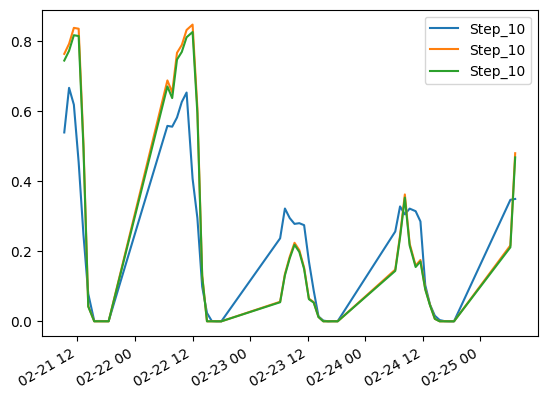

In [76]:
pv_ts.columns = [y.columns[10]]
pd.concat([predictions.loc[dates[1000:1200:4], y.columns[10]], y.loc[dates[1000:1200:4], y.columns[10]], pv_ts.loc[dates[1000:1200:4], y.columns[10]] / 175], axis=1).plot()


In [73]:
pv_ts

,Step_10
2025-02-01 06:15:00,121.363
2025-02-01 06:30:00,121.913
2025-02-01 06:45:00,121.042
2025-02-01 07:00:00,120.110
2025-02-01 07:15:00,116.574
...,...
2025-03-20 05:45:00,83.595
2025-03-20 06:00:00,68.101
2025-03-20 06:15:00,64.801
2025-03-20 06:30:00,67.758


In [77]:
pv_ts

,Step_10
2025-02-01 06:15:00,121.363
2025-02-01 06:30:00,121.913
2025-02-01 06:45:00,121.042
2025-02-01 07:00:00,120.110
2025-02-01 07:15:00,116.574
...,...
2025-03-20 05:45:00,83.595
2025-03-20 06:00:00,68.101
2025-03-20 06:15:00,64.801
2025-03-20 06:30:00,67.758
